# temp file
Test for a single field & tomo bin. run 100 random rotations for simplicity

In [1]:
import os
os.chdir('/home/hedi/HSCNG/')
import multiprocessing as mp

import numpy as np
from astropy.coordinates import SkyCoord
from astropy.io import fits
from astropy.wcs import WCS
from astropy import units as u
import pymaster as nmt
import tqdm

from hsc_y3_utils import map_utils
import matplotlib.pyplot as plt

# use -g2 in power spectrum calculation.


name_fields = ['XMM', 'VVDS', 'GAMA09H', 'GAMA15H', 'WIDE12H', 'HECTOMAP']
number_patches = [8, 25, 23, 7, 26, 13]
tomo_bin = [1, 2, 3, 4]
pixscale_arcmin = 0.5   # 0.5 arcmin → degrees/pixel
pixscale_deg = pixscale_arcmin / 60.0
smoothing_kernel_size = 1   # arcmin

smooth = True

ell_min = 80
ell_max = 6500
n_bins = 20

In [2]:
def _compute_spin2_power(g1_map, g2_map, mask_z, size_rad_x, size_rad_y, bins, wsp):
    field = nmt.NmtFieldFlat(size_rad_x, size_rad_y, mask_z, [g1_map, -g2_map])         # MULTIPLY -1 HERE
    cl_coupled = nmt.compute_coupled_cell_flat(field, field, bins)
    ee, eb, _, bb = wsp.decouple_cell(cl_coupled)
    return ee, bb, eb

In [3]:
field = 'XMM'
tomo = 2
npro = -1
print(f'Processing field: {field}')
print('Loading data...')

# 1 data loading
npatch = number_patches[name_fields.index(field)]
dats = [
    fits.getdata(f'data/real/hscy3_shape_chopped_{field}_{i}.fits')
    for i in range(npatch)
]
dat = np.concatenate(dats)
dat = dat[np.isin(dat['hsc_y3_zbin'], np.atleast_1d(tomo))]

ra = dat['i_ra']
dec = dat['i_dec']
padding = 10

w, (nx, ny) = map_utils.set_wcs_shape(ra, dec, pixscale_arcmin, padding)

print('Image size:', nx, 'x', ny)

Processing field: XMM
Loading data...
Image size: 1260 x 645


In [65]:
import importlib
importlib.reload(map_utils)

<module 'hsc_y3_utils.map_utils' from '/misc/home/hedi/HSCNG/hsc_y3_utils/map_utils.py'>

In [4]:
# 2 shear map
print('Creating shear maps...')

flatgrid = map_utils.FlatClass(wcs=w, nx=nx, ny=ny)
ra_cat = dat['i_ra']
dec_cat = dat['i_dec']
weight_cat = dat['i_hsmshaperegauss_derived_weight']
m_cat = dat['i_hsmshaperegauss_derived_shear_bias_m']
erms_cat = dat['i_hsmshaperegauss_derived_rms_e']

e1_cat = dat['i_hsmshaperegauss_e1']
e2_cat = dat['i_hsmshaperegauss_e2']
c1_cat = dat['i_hsmshaperegauss_derived_shear_bias_c1']
c2_cat = dat['i_hsmshaperegauss_derived_shear_bias_c2']
flux_cat = dat['i_apertureflux_10_mag']
res_cat = dat['i_hsmshaperegauss_resolution']

psf11 = dat['i_sdssshape_psf_shape11']
psf12 = dat['i_sdssshape_psf_shape12']
psf22 = dat['i_sdssshape_psf_shape22']
epsf1_cat = (psf11 - psf22) / (psf11 + psf22)
epsf2_cat = (2 * psf12) / (psf11 + psf22)

e1_hat, e2_hat = map_utils.calib_shear_y3(
    weight_cat,
    m_cat,
    erms_cat,
    e1_cat,
    e2_cat,
    c1_cat,
    c2_cat,
    flux_cat,
    res_cat,
    epsf1_cat,
    epsf2_cat,
)

[g1_map, g2_map], [mask, _] = map_utils.create_shear_map(
    ra_cat,
    dec_cat,
    e1_hat,
    e2_hat,
    flatgrid,
    weights=weight_cat,
)

mask_z = flatgrid.transform_mapsize(mask)
g1_map = flatgrid.transform_mapsize(g1_map)
g2_map = flatgrid.transform_mapsize(g2_map)

smoothing_pixels = smoothing_kernel_size / (pixscale_deg * 60)
g1_map_smooth = flatgrid.smooth_G_masked(g1_map, mask_z, smoothing_pixels)
g2_map_smooth = flatgrid.smooth_G_masked(g2_map, mask_z, smoothing_pixels)

# if smooth:
#     smoothing_pixels = smoothing_kernel_size / (pixscale_deg * 60)
#     g1_map = flatgrid.smooth_G_masked(g1_map, mask_z, smoothing_pixels)
#     g2_map = flatgrid.smooth_G_masked(g2_map, mask_z, smoothing_pixels)
    # g1_map = flatgrid.smooth_G(g1_map, smoothing_pixels)
    # g2_map = flatgrid.smooth_G(g2_map, smoothing_pixels)


Creating shear maps...


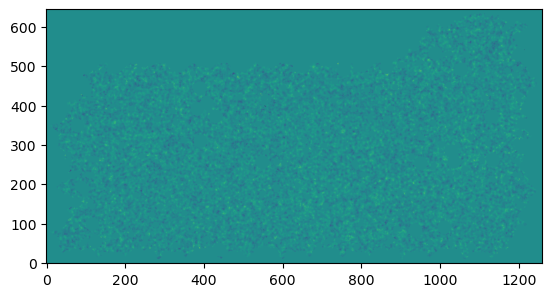

In [5]:
plt.imshow(g1_map_smooth, origin='lower')

In [84]:
from scipy.ndimage import filters

num = filters.gaussian_filter(g1_map * mask_z, 2)
den = filters.gaussian_filter(mask_z.astype(float), 2)

out = np.zeros_like(num)
good = den > 0
out[good] = num[good] / den[good]

/var/tmp/pbs.571294.idark/ipykernel_43112/1131670207.py:3: DeprecationWarning: Please import `gaussian_filter` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  num = filters.gaussian_filter(g1_map * mask_z, 2)
/var/tmp/pbs.571294.idark/ipykernel_43112/1131670207.py:4: DeprecationWarning: Please import `gaussian_filter` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  den = filters.gaussian_filter(mask_z.astype(float), 2)


In [85]:
mid = np.percentile(den[den>0], 5)

(array([4.0000e+00, 2.0000e+00, 1.0000e+01, 1.5000e+01, 1.2000e+01,
        2.5000e+01, 4.3000e+01, 8.0000e+01, 1.1100e+02, 1.6300e+02,
        2.3200e+02, 3.2700e+02, 3.9900e+02, 5.9400e+02, 7.5300e+02,
        1.0010e+03, 1.4030e+03, 1.6550e+03, 2.1210e+03, 2.7650e+03,
        3.4370e+03, 4.4770e+03, 5.3610e+03, 6.8270e+03, 8.2280e+03,
        1.0086e+04, 1.1747e+04, 1.3717e+04, 1.5522e+04, 1.7328e+04,
        1.9032e+04, 2.0053e+04, 2.0965e+04, 2.1006e+04, 2.1103e+04,
        2.0141e+04, 1.9026e+04, 1.6902e+04, 1.4988e+04, 1.2403e+04,
        9.9280e+03, 7.8120e+03, 5.6120e+03, 3.8870e+03, 2.3650e+03,
        1.3850e+03, 6.4200e+02, 2.7600e+02, 1.0700e+02, 5.7000e+01]),
 array([0.04051892, 0.05941001, 0.07830109, 0.09719218, 0.11608327,
        0.13497436, 0.15386545, 0.17275654, 0.19164763, 0.21053872,
        0.22942981, 0.2483209 , 0.26721199, 0.28610307, 0.30499416,
        0.32388525, 0.34277634, 0.36166743, 0.38055852, 0.39944961,
        0.4183407 , 0.43723179, 0.45612288, 0.

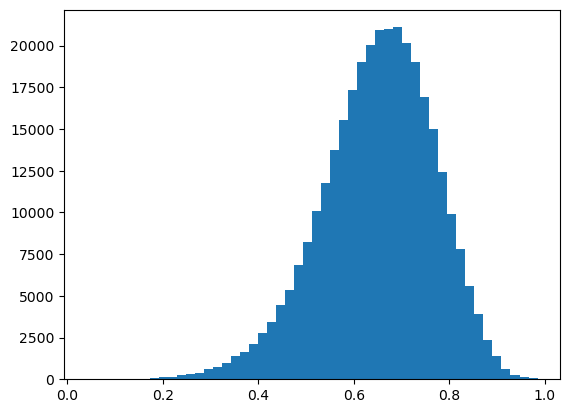

In [87]:
plt.hist(den[(den>0) & (mask_z==1)], bins=50)

In [5]:
# 3 workspace
size_rad_x = pixscale_deg / 180.0 * np.pi * nx
size_rad_y = pixscale_deg / 180.0 * np.pi * ny
ell_edges = np.unique(np.logspace(np.log10(ell_min), np.log10(ell_max), n_bins))
bins = nmt.bins.NmtBinFlat(ell_edges[:-1], ell_edges[1:])
ells_uncoupled = bins.get_effective_ells()

f0 = nmt.NmtFieldFlat(size_rad_x, size_rad_y, mask_z, [g1_map, -g2_map])
wsp = nmt.NmtWorkspaceFlat()
wsp.compute_coupling_matrix(f0, f0, bins)

In [67]:
ee, bb, eb = _compute_spin2_power(g1_map, g2_map, mask_z, size_rad_x, size_rad_y, bins, wsp)
cls_data = {
    'EE': ee,
    'EB': eb,
    'BB': bb,
}

In [68]:
cls_data

{'EE': array([8.02936347e-09, 2.13539495e-09, 3.75734857e-09, 2.89572076e-09,
        3.27199627e-09, 2.71841357e-09, 2.46454821e-09, 2.66271227e-09,
        1.82709265e-09, 2.12832741e-09, 2.09484150e-09, 1.82030144e-09,
        1.82166123e-09, 1.49718859e-09, 1.18829342e-09, 9.43328570e-10,
        6.34646420e-10, 3.34910127e-10, 1.23119609e-10]),
 'EB': array([-8.05270594e-09,  2.39822965e-09,  9.52410676e-10,  6.70837045e-10,
        -3.75246704e-10, -1.73194009e-10, -6.22537157e-10,  1.32050934e-10,
        -2.05432309e-10, -1.01019709e-10,  5.24957799e-11,  1.63375462e-11,
         4.43775664e-11,  7.13052421e-12, -1.56703535e-11, -3.34180939e-12,
         2.46654516e-13,  3.39560953e-12,  5.26387321e-13]),
 'BB': array([1.03982720e-08, 3.89432067e-09, 1.28563518e-09, 2.20837826e-09,
        1.36907241e-09, 2.14973702e-09, 1.78319408e-09, 1.95574889e-09,
        2.21492957e-09, 1.87231353e-09, 1.69613840e-09, 1.72524779e-09,
        1.58510233e-09, 1.46740314e-09, 1.20798383e-09,

In [69]:
# 4 shot noise
n_rand = 100
rand_ee = []
rand_bb = []
rand_eb = []

for i in range(n_rand):
    e1_ran, e2_ran = map_utils.random_rotation(e1_hat, e2_hat)
    [g1_map, g2_map], [mask, _] = map_utils.create_shear_map(
        ra_cat,
        dec_cat,
        e1_ran,
        e2_ran,
        flatgrid,
        weights=weight_cat,
    )
    mask_z = flatgrid.transform_mapsize(mask)
    g1_map = flatgrid.transform_mapsize(g1_map)
    g2_map = flatgrid.transform_mapsize(g2_map)
    if smooth:
        smoothing_pixels = smoothing_kernel_size / (pixscale_deg * 60)
        g1_map = flatgrid.smooth_G_masked(g1_map, mask_z, smoothing_pixels)
        g2_map = flatgrid.smooth_G_masked(g2_map, mask_z, smoothing_pixels)
        # g1_map = flatgrid.smooth_G(g1_map, smoothing_pixels)
        # g2_map = flatgrid.smooth_G(g2_map, smoothing_pixels)

    ee_r, bb_r, eb_r = _compute_spin2_power(g1_map, g2_map, mask_z, size_rad_x, size_rad_y, bins, wsp)
    rand_ee.append(ee_r)
    rand_bb.append(bb_r)
    rand_eb.append(eb_r)


rand_ee = np.array(rand_ee)
rand_bb = np.array(rand_bb)
rand_eb = np.array(rand_eb)

ee_rm = rand_ee.mean(axis=0)
ee_std = rand_ee.std(axis=0)
bb_rm = rand_bb.mean(axis=0)
bb_std = rand_bb.std(axis=0)
eb_rm = rand_eb.mean(axis=0)
eb_std = rand_eb.std(axis=0)

cls_random_mean = {
    'EE': ee_rm,
    'EB': eb_rm,
    'BB': bb_rm,
}

In [70]:
np.savetxt(
    f'tmp/Cl_results_{field}_smooth_g_z{tomo}_comp_smooth_{smooth}.txt',
    np.vstack([ells_uncoupled, cls_data['EE'], cls_data['EB'], cls_data['BB'], ee_rm, ee_std, eb_rm, eb_std, bb_rm, bb_std]).T,
)

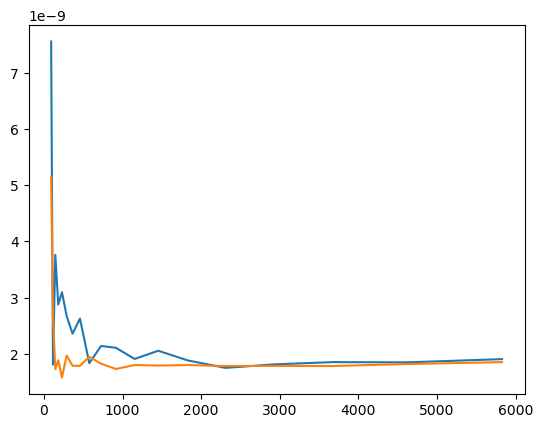

In [ ]:
plt.plot(ells_uncoupled, cls_data['EE'], label='EE')
plt.plot(ells_uncoupled, cls_random_mean['EE'], label='EE random mean')

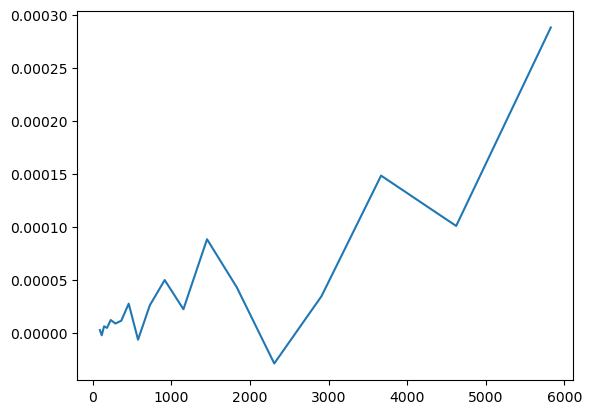

In [88]:
plt.plot(ells_uncoupled, (cls_data['EE'] - cls_random_mean['EE']) * ells_uncoupled * (ells_uncoupled + 1) / (2 * np.pi), label='EE (l(l+1)/2pi)')

# COMPARISON
The difference seems to come from smoothing.

Text(0.5, 1.0, 'XMM z2 comparison smooth vs unsmooth')

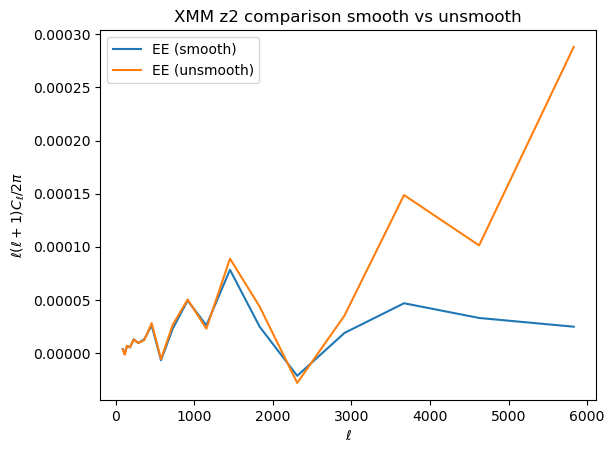

In [81]:
field = 'XMM'
tomo = 2

array2dict_k = lambda arr: {['ls', 'EE', 'EB', 'BB', 'EE_rm', 'EE_std', 'EB_rm', 'EB_std', 'BB_rm', 'BB_std'][i]: arr[:, i] for i in range(arr.shape[1])}

res_smooth = array2dict_k(np.loadtxt(f'tmp/Cl_results_{field}_smooth_g_z{tomo}_comp_smooth_True.txt'))
res_unsmooth = array2dict_k(np.loadtxt(f'tmp/Cl_results_{field}_smooth_g_z{tomo}_comp_smooth_False.txt'))

plt.plot(res_smooth['ls'], (res_smooth['EE'] - res_smooth['EE_rm']) * res_smooth['ls'] * (res_smooth['ls'] + 1) / 2 / np.pi, label='EE (smooth)')
plt.plot(res_unsmooth['ls'], (res_unsmooth['EE'] - res_unsmooth['EE_rm']) * res_unsmooth['ls'] * (res_unsmooth['ls'] + 1) / 2 / np.pi, label='EE (unsmooth)')

plt.legend()
plt.xlabel(r'$\ell$')
plt.ylabel(r'$\ell(\ell+1)C_\ell/2\pi$')

plt.title(f'{field} z{tomo} comparison smooth vs unsmooth')

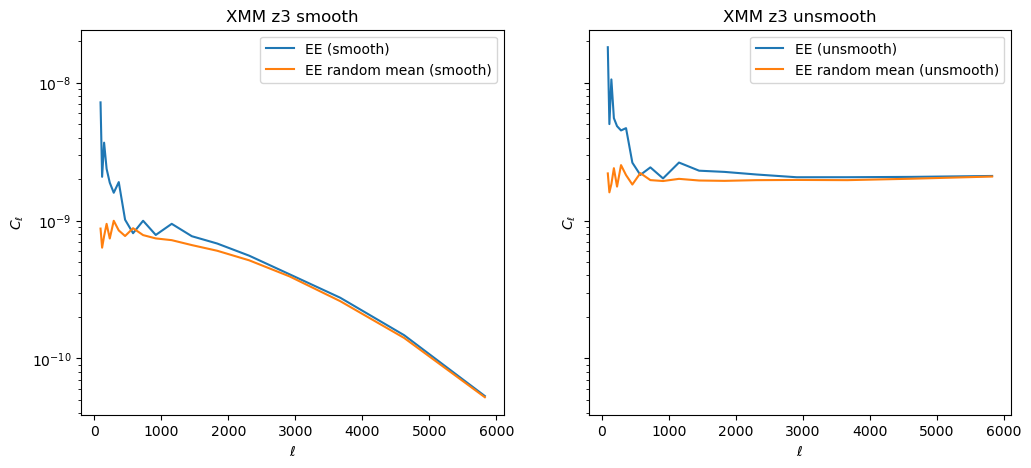

In [103]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
axes[0].plot(res_smooth['ls'], res_smooth['EE'], label='EE (smooth)')
axes[0].plot(res_smooth['ls'], res_smooth['EE_rm'], label='EE random mean (smooth)')
axes[0].set_xlabel(r'$\ell$')
axes[0].set_ylabel(r'$C_\ell$')
axes[0].legend()
axes[0].set_title(f'{field} z{tomo} smooth')

axes[0].hlines(0, res_smooth['ls'][0], res_smooth['ls'][-1], colors='gray', linestyles='dashed')
axes[0].set_yscale('log')

axes[1].plot(res_unsmooth['ls'], res_unsmooth['EE'], label='EE (unsmooth)')
axes[1].plot(res_unsmooth['ls'], res_unsmooth['EE_rm'], label='EE random mean (unsmooth)')
axes[1].set_xlabel(r'$\ell$')
axes[1].set_ylabel(r'$C_\ell$')
axes[1].legend()
axes[1].set_title(f'{field} z{tomo} unsmooth')

axes[1].hlines(0, res_unsmooth['ls'][0], res_unsmooth['ls'][-1], colors='gray', linestyles='dashed')

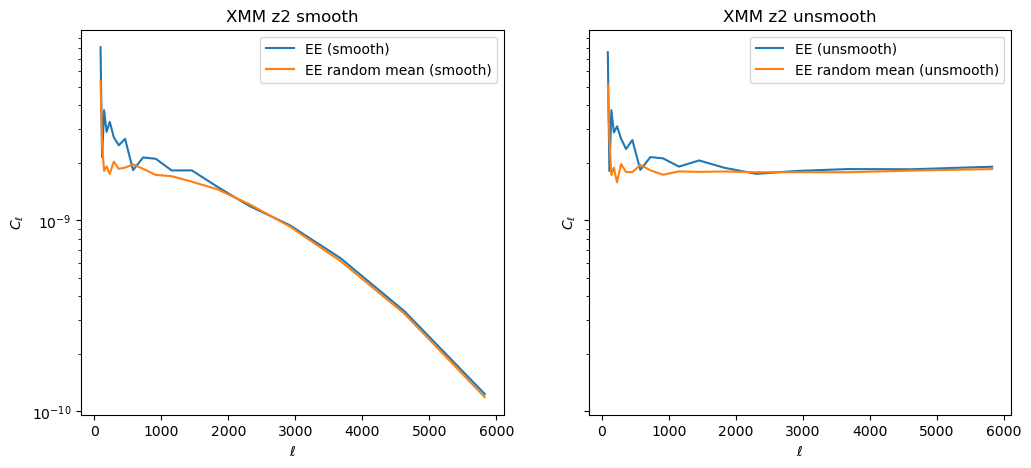

In [71]:
field = 'XMM'
tomo = 2

array2dict_k = lambda arr: {['ls', 'EE', 'EB', 'BB', 'EE_rm', 'EE_std', 'EB_rm', 'EB_std', 'BB_rm', 'BB_std'][i]: arr[:, i] for i in range(arr.shape[1])}

res_smooth = array2dict_k(np.loadtxt(f'tmp/Cl_results_{field}_smooth_g_z{tomo}_comp_smooth_True.txt'))
res_unsmooth = array2dict_k(np.loadtxt(f'tmp/Cl_results_{field}_smooth_g_z{tomo}_comp_smooth_False.txt'))


fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
axes[0].plot(res_smooth['ls'], res_smooth['EE'], label='EE (smooth)')
axes[0].plot(res_smooth['ls'], res_smooth['EE_rm'], label='EE random mean (smooth)')
axes[0].set_xlabel(r'$\ell$')
axes[0].set_ylabel(r'$C_\ell$')
axes[0].legend()
axes[0].set_title(f'{field} z{tomo} smooth')

axes[0].hlines(0, res_smooth['ls'][0], res_smooth['ls'][-1], colors='gray', linestyles='dashed')
axes[0].set_yscale('log')

axes[1].plot(res_unsmooth['ls'], res_unsmooth['EE'], label='EE (unsmooth)')
axes[1].plot(res_unsmooth['ls'], res_unsmooth['EE_rm'], label='EE random mean (unsmooth)')
axes[1].set_xlabel(r'$\ell$')
axes[1].set_ylabel(r'$C_\ell$')
axes[1].legend()
axes[1].set_title(f'{field} z{tomo} unsmooth')

axes[1].hlines(0, res_unsmooth['ls'][0], res_unsmooth['ls'][-1], colors='gray', linestyles='dashed')

In [90]:
field = 'XMM'
tomo = 2

res_smooth = array2dict_k(np.loadtxt(f'tmp/Cl_results_{field}_smooth_g_z{tomo}_comp_smooth_True.txt'))
res_unsmooth = array2dict_k(np.loadtxt(f'tmp/Cl_results_{field}_smooth_g_z{tomo}_comp_smooth_False.txt'))
res_legacy = array2dict_k(np.loadtxt(f"results/Cl_results_{field}_smooth_g_z{tomo}_negg2_smooth.txt"))
res = array2dict_k(np.loadtxt(f"results/Cl_results_{field}_smooth_g_z{tomo}_negg2_cmp.txt"))

In [91]:
ls = np.linspace(ell_min, ell_max, 100)

sigma_arcmin = 1.0
sigma_rad = np.deg2rad(sigma_arcmin / 60.0)
B_ell = np.exp(-0.5 * ls**2 * sigma_rad**2)
W_cl = B_ell**2

In [92]:
(res_legacy['EE'] / (res['EE'] * (np.exp(-0.5 * res['ls']**2 * sigma_rad**2))**2)).mean()

np.float64(0.4457617395781637)

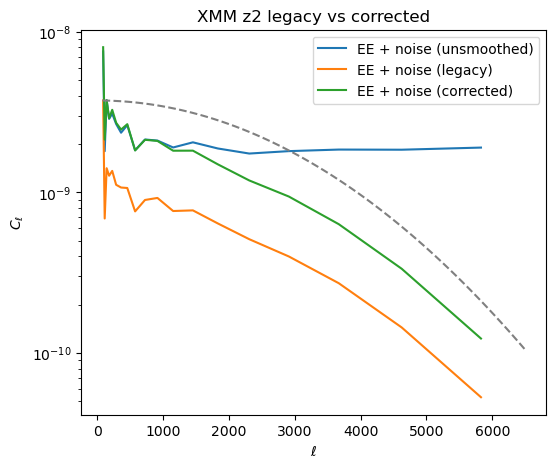

In [99]:
fig = plt.figure(figsize=(6, 5))
axes = fig.subplots(1, 1)

axes.plot(res['ls'], res['EE'], label='EE + noise (unsmoothed)')

axes.plot(res_legacy['ls'], res_legacy['EE'], label='EE + noise (legacy)')
axes.plot(res_smooth['ls'], res_smooth['EE'], label='EE + noise (corrected)')

# axes.plot(res['ls'], res['EE'] * (np.exp(-0.5 * res['ls']**2 * sigma_rad**2))**2, label='EE + noise (corrected)')

axes.plot(ls, W_cl * res_legacy['EE'][0], '--', color='gray')

axes.legend()

axes.set_xlabel(r'$\ell$')
axes.set_ylabel(r'$C_\ell$')
axes.set_title(f'{field} z{tomo} legacy vs corrected')

axes.set_yscale('log')

Text(0.5, 1.0, 'XMM z2 comparison legacy vs corrected')

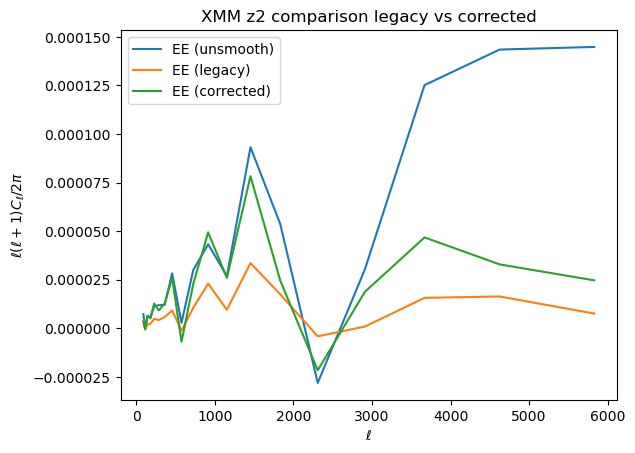

In [100]:
plt.plot(res['ls'], (res['EE'] - res['EE_rm']) * res['ls'] * (res['ls'] + 1) / 2 / np.pi, label='EE (unsmooth)')

plt.plot(res_legacy['ls'], (res_legacy['EE'] - res_legacy['EE_rm']) * res_legacy['ls'] * (res_legacy['ls'] + 1) / 2 / np.pi, label='EE (legacy)')
plt.plot(res_smooth['ls'], (res_smooth['EE'] - res_smooth['EE_rm']) * res_smooth['ls'] * (res_smooth['ls'] + 1) / 2 / np.pi, label='EE (corrected)')

plt.legend()
plt.xlabel(r'$\ell$')
plt.ylabel(r'$\ell(\ell+1)C_\ell/2\pi$')

plt.title(f'{field} z{tomo} comparison legacy vs corrected')